# Evaluation of the CNN Image Only Model
After training on Colab, results were then saved in Drive, then saved locally. Those results are evaluated here. The same metrics and plots from `03_clinical_model.ipynb` were done here as well as plotting the fold to fold loss functions to evaluate overfitting. 

A more in-depth and cleaner version of this notebook with markdowns will be done later. 

In [1]:
import pandas as pd
from src.cohort import build_cohort
from src.config import PROJECT_ROOT

CNN_DIR = PROJECT_ROOT / "results" / "cnn"
cohort = build_cohort(expected_n=617, verbose=False)
pred = pd.concat([pd.read_csv(CNN_DIR / f"fold{k}_pred.csv") for k in range(5)], ignore_index=True)

# Every usable patient exactly once; folds and labels agree with the manifest; probabilities are valid
assert len(pred) == 617 and pred["patient_id"].is_unique
check = pred.merge(cohort[["patient_id", "fold", "idh"]], on="patient_id", suffixes=("", "_manifest"))
assert len(check) == 617
assert (check["fold"] == check["fold_manifest"]).all() and (check["idh"] == check["idh_manifest"]).all()
assert pred["cnn_prob"].between(0, 1).all()

# Add the CNN column to the shared out-of-fold file (safe to re-run)
oof_path = PROJECT_ROOT / "results" / "oof_predictions.csv"
oof = pd.read_csv(oof_path).drop(columns="image_cnn_prob", errors="ignore")
oof = oof.merge(pred[["patient_id", "cnn_prob"]].rename(columns={"cnn_prob": "image_cnn_prob"}),
                on="patient_id", how="left")
assert oof["image_cnn_prob"].notna().all()
oof.to_csv(oof_path, index=False)
print("stitched 617 predictions; ids, folds and labels match the manifest")

stitched 617 predictions; ids, folds and labels match the manifest


In [2]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from src.metrics import threshold_predictions, summarize, bootstrap_ci, paired_auroc_difference

oof = pd.read_csv(oof_path)
y, folds = oof["idh"].to_numpy(), oof["fold"].to_numpy()
prob_cnn, prob_age = oof["image_cnn_prob"].to_numpy(), oof["clinical_age_prob"].to_numpy()

pred = threshold_predictions(prob_cnn, y, folds)
row = {"model": "image_cnn", "n_patients": len(y), **summarize(y, prob_cnn, pred)}
row["auroc_ci_low"], row["auroc_ci_high"] = bootstrap_ci(y, prob_cnn, roc_auc_score)
row["pr_auc_ci_low"], row["pr_auc_ci_high"] = bootstrap_ci(y, prob_cnn, average_precision_score)
comparison_row = pd.DataFrame([row]).round(3)
print(comparison_row.set_index("model").T)
print("prevalence (PR-AUC baseline):", round(y.mean(), 3),
      "| Brier of always predicting prevalence:", round(y.mean() * (1 - y.mean()), 3))

fold_auroc = [roc_auc_score(y[folds == k], prob_cnn[folds == k]) for k in np.unique(folds)]
print("per-fold AUROC:", np.round(fold_auroc, 3))

diff, (lo, hi) = paired_auroc_difference(y, prob_cnn, prob_age)
print(f"AUROC image CNN minus age-only: {diff:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

# Save the CNN row next to the clinical rows (safe to re-run)
cmp_path = PROJECT_ROOT / "results" / "model_comparison.csv"
old = pd.read_csv(cmp_path)
pd.concat([old[old["model"] != "image_cnn"], comparison_row], ignore_index=True).to_csv(cmp_path, index=False)

model           image_cnn
n_patients        617.000
auroc               0.888
pr_auc              0.809
brier               0.111
accuracy            0.799
precision           0.611
recall              0.800
specificity         0.799
auroc_ci_low        0.856
auroc_ci_high       0.917
pr_auc_ci_low       0.750
pr_auc_ci_high      0.860
prevalence (PR-AUC baseline): 0.284 | Brier of always predicting prevalence: 0.203
per-fold AUROC: [0.85  0.942 0.946 0.835 0.9  ]
AUROC image CNN minus age-only: +0.008 (95% CI -0.030 to +0.042)


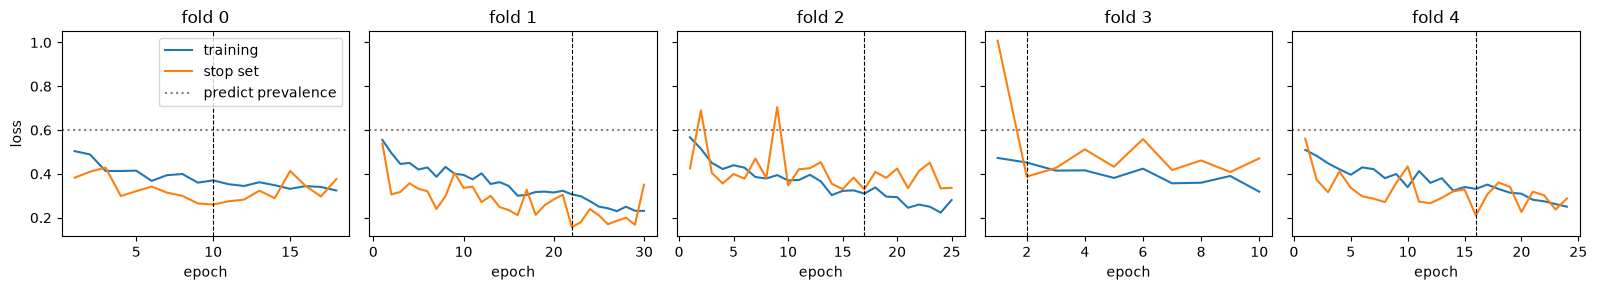

In [3]:
import matplotlib.pyplot as plt

h = pd.read_csv(CNN_DIR / "history.csv")
runs = pd.read_csv(CNN_DIR / "runs.csv")
best = runs[runs["mode"] == "final"].set_index("fold")["best_epoch"]

groups = list(h[h["mode"] == "final"].groupby("fold"))
fig, axes = plt.subplots(1, len(groups), figsize=(3.2 * len(groups), 3), sharey=True, squeeze=False)
for ax, (fold, g) in zip(axes[0], groups):
    ax.plot(g["epoch"], g["train_loss"], label="training")
    ax.plot(g["epoch"], g["stop_loss"], label="stop set")
    ax.axhline(0.60, color="gray", ls=":", label="predict prevalence")
    ax.axvline(best[fold], color="k", ls="--", lw=0.8)
    ax.set(title=f"fold {fold}", xlabel="epoch")
axes[0][0].set_ylabel("loss"); axes[0][0].legend()
plt.tight_layout()
plt.show()

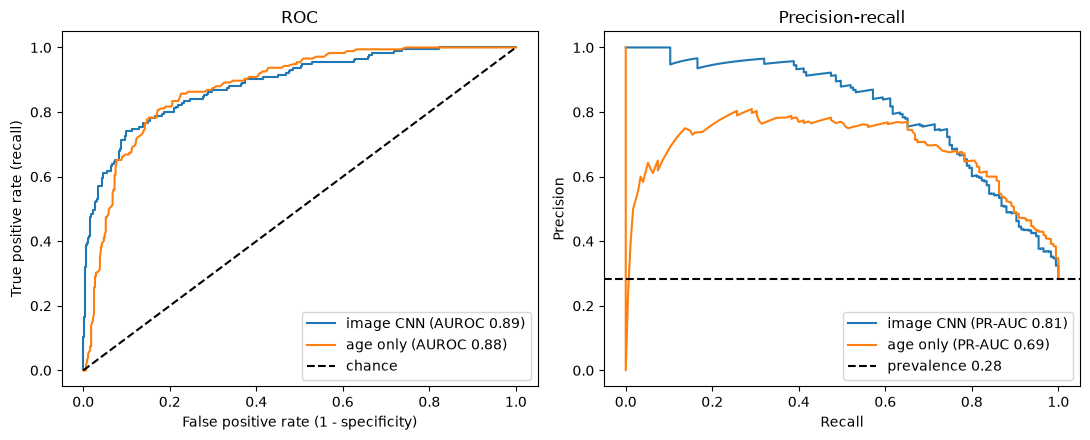

In [4]:
from sklearn.calibration import calibration_curve

models = {"image CNN": prob_cnn, "age only": prob_age}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in models.items():
    fpr, tpr, _ = roc_curve(y, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y, prob):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)", title="ROC")
axes[1].axhline(y.mean(), color="k", ls="--", label=f"prevalence {y.mean():.2f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

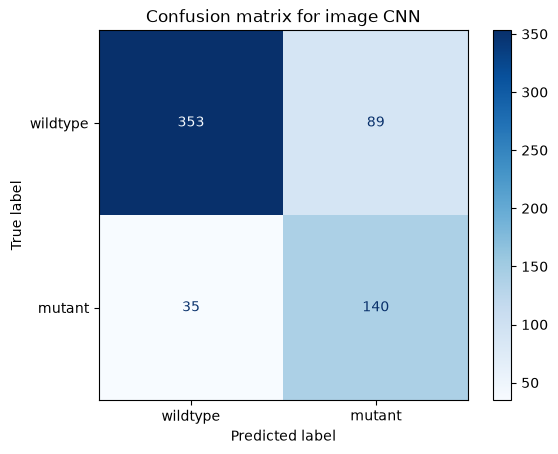

In [5]:
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["wildtype", "mutant"]).plot(
    cmap="Blues", values_format="d")
plt.title("Confusion matrix for image CNN")
plt.show()

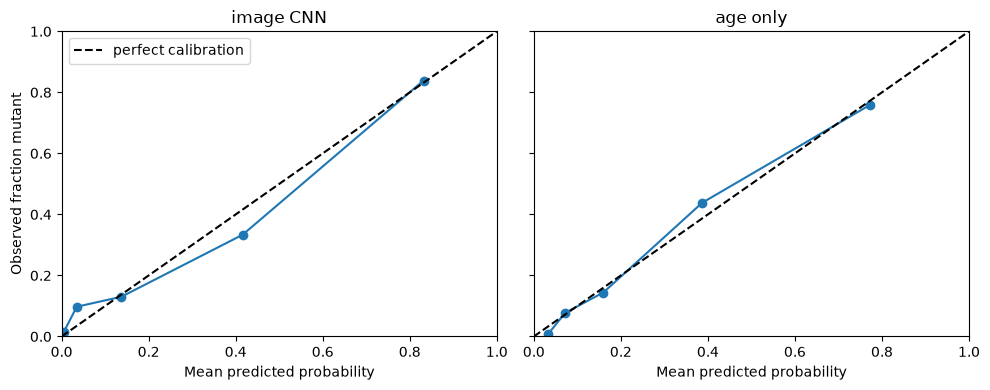

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, (name, prob) in zip(axes, models.items()):
    observed, predicted = calibration_curve(y, prob, n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o")
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set(xlabel="Mean predicted probability", title=name, xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed fraction mutant")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()